# CS4186 Integrated Project

In [1]:
from pathlib import Path
import zipfile, io, json, csv, random
import numpy as np
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
from IPython.display import display, Image
SEED=4186
EPOCHS=12
LATENT=8
BATCH=128
LR=0.001
BETA=1
LEVELS=(0.15,0.30)
SIGMA=0.8
OUT=Path('project_outputs'); OUT.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(2)
device=torch.device('cpu')
config=dict(seed=SEED, noise_seed=4187, prior_seed=391, validation_seed=724, epochs=EPOCHS, latent_dim=LATENT, batch_size=BATCH, learning_rate=LR, beta=BETA, noise_levels=LEVELS, filter_sigma=SIGMA, kernel_size=3, padding='reflect', device=str(device), torch_version=str(torch.__version__), numpy_version=np.__version__, display_indices=list(range(8)), interpolation_indices=[0,1])
(OUT/'config.json').write_text(json.dumps(config,indent=2))

502

In [2]:
relative=Path('Tutorial_08_CV_Latent_Models/data/mnist_binary_subset.npz')
if relative.exists():
    source=relative
elif Path('data/mnist_binary_subset.npz').exists():
    source=Path('data/mnist_binary_subset.npz')
elif Path("Tutorial_08_CV_Latent_Models.zip").is_file():
    with zipfile.ZipFile('Tutorial_08_CV_Latent_Models.zip') as archive:
        matches = [name for name in archive.namelist()
                   if name.replace(chr(92), '/').split('/')[-1] == 'mnist_binary_subset.npz']
        if len(matches) != 1:
            raise ValueError(f'Expected one dataset, found: {matches}')
        source = io.BytesIO(archive.read(matches[0]))
else:
    raise FileNotFoundError(f"Place Tutorial_08_CV_Latent_Models.zip beside the notebook. Current directory: {Path.cwd()}")
with np.load(source) as data:
    train,val,test=[torch.from_numpy(data['x_'+s].copy()).float().unsqueeze(1) for s in ('train','val','test')]
for x,count in zip((train,val,test),(5000,1000,1000)):
    assert x.shape==(count,1,28,28) and ((x==0)|(x==1)).all()
    print(x.shape)

torch.Size([5000, 1, 28, 28])
torch.Size([1000, 1, 28, 28])
torch.Size([1000, 1, 28, 28])


In [3]:
def gaussian_kernel(sigma=SIGMA):
    a=torch.arange(-1,2,dtype=torch.float32)
    yy,xx=torch.meshgrid(a,a,indexing='ij')
    k=torch.exp(-(xx.square()+yy.square())/(2*sigma**2))
    return k/k.sum()
def apply_kernel(x,k):
    return F.conv2d(F.pad(x,(1,1,1,1),mode='reflect'),k.to(x).reshape(1,1,3,3))
def gaussian(x):
    return apply_kernel(x,gaussian_kernel())
def sobel(x):
    k=torch.tensor([[-1.,0,1],[-2,0,2],[-1,0,1]])
    gx,gy=apply_kernel(x,k),apply_kernel(x,k.T)
    return gx,gy,torch.sqrt(gx.square()+gy.square())
noise=torch.randn(test.shape,generator=torch.Generator().manual_seed(4187))
noisy={s:(test+s*noise).clamp(0,1) for s in LEVELS}
assert torch.allclose(gaussian_kernel().sum(),torch.tensor(1.))
assert torch.allclose(gaussian(torch.ones(1,1,28,28)),torch.ones(1,1,28,28))
assert sobel(torch.ones(1,1,28,28))[2].max()==0
print(gaussian_kernel())

tensor([[0.0571, 0.1248, 0.0571],
        [0.1248, 0.2725, 0.1248],
        [0.0571, 0.1248, 0.0571]])


In [4]:
class ConvVAE(nn.Module):
    def __init__(self,latent_dim=8):
        super().__init__(); self.latent_dim=latent_dim
        self.encoder=nn.Sequential(nn.Conv2d(1,16,4,2,1),nn.ReLU(),
            nn.Conv2d(16,32,4,2,1),nn.ReLU(),nn.Flatten(),nn.Linear(32*7*7,64),nn.ReLU())
        self.mu=nn.Linear(64,latent_dim); self.logvar=nn.Linear(64,latent_dim)
        self.decoder_input=nn.Sequential(nn.Linear(latent_dim,64),nn.ReLU(),nn.Linear(64,32*7*7),nn.ReLU())
        self.decoder=nn.Sequential(nn.ConvTranspose2d(32,16,4,2,1),nn.ReLU(),nn.ConvTranspose2d(16,1,4,2,1))
    def encode(self,x):
        h=self.encoder(x)
        return self.mu(h),self.logvar(h).clamp(-8,6)
    def decode(self,z):
        return self.decoder(self.decoder_input(z).reshape(-1,32,7,7))

In [5]:
def sample_latent(mu,logvar,eps=None):
    if eps is None: eps=torch.randn_like(mu)
    return mu+torch.exp(0.5*logvar)*eps
def per_image_bce(logits,targets):
    return F.binary_cross_entropy_with_logits(logits,targets,reduction='none').flatten(1).sum(1)
def kl_diag(mu,logvar):
    return -0.5*(1+logvar-mu.square()-logvar.exp()).sum(-1)
mu=torch.tensor([[1.,0.]],requires_grad=True); lv=torch.tensor([[np.log(.25),0.]],dtype=torch.float32,requires_grad=True)
z=sample_latent(mu,lv,torch.ones_like(mu))
torch.testing.assert_close(z,torch.tensor([[1.5,1.]]))
gm,gl=torch.autograd.grad(z.sum(),(mu,lv))
torch.testing.assert_close(gl,torch.tensor([[.25,.5]]))
torch.testing.assert_close(kl_diag(mu,lv),torch.tensor([.81814718]))
torch.testing.assert_close(per_image_bce(torch.zeros(2,1,2,2),torch.ones(2,1,2,2)),torch.full((2,),4*np.log(2)))

In [6]:
torch.manual_seed(SEED)
model=ConvVAE(LATENT).to(device)
optimizer=torch.optim.Adam(model.parameters(),lr=LR)
loader=DataLoader(TensorDataset(train),batch_size=BATCH,shuffle=True,generator=torch.Generator().manual_seed(SEED))
@torch.no_grad()
def validate():
    model.eval(); rng=torch.Generator().manual_seed(724); totals=np.zeros(2)
    for x in val.split(BATCH):
        mu,lv=model.encode(x); eps=torch.randn(mu.shape,generator=rng)
        r=per_image_bce(model.decode(sample_latent(mu,lv,eps)),x)
        totals += [r.sum().item(),kl_diag(mu,lv).sum().item()]
    return totals/len(val)
history=[]; best=float('inf')
for epoch in range(1,EPOCHS+1):
    model.train(); totals=np.zeros(2)
    for (x,) in loader:
        mu,lv=model.encode(x)
        r=per_image_bce(model.decode(sample_latent(mu,lv)),x); k=kl_diag(mu,lv)
        loss=(r+BETA*k).mean()
        optimizer.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(),5); optimizer.step()
        totals += [r.detach().sum().item(),k.detach().sum().item()]
    tr,tk=totals/len(train); vr,vk=validate()
    history.append(dict(epoch=epoch,train_reconstruction=tr,train_kl=tk,val_reconstruction=vr,val_kl=vk))
    if vr+vk<best:
        best=vr+vk; selected=epoch
        torch.save(dict(state_dict=model.state_dict(),latent_dim=LATENT,selected_epoch=epoch),OUT/'vae.pt')
    print(f'Epoch {epoch:02d}: train R={tr:.2f}, KL={tk:.2f}; val ELBO loss={vr+vk:.2f}')
with (OUT/'training.csv').open('w',newline='') as f:
    w=csv.DictWriter(f,fieldnames=history[0]); w.writeheader(); w.writerows(history)
print('Selected epoch:',selected)

Epoch 01: train R=403.57, KL=7.40; val ELBO loss=233.63
Epoch 02: train R=211.91, KL=3.09; val ELBO loss=202.97
Epoch 03: train R=195.87, KL=2.78; val ELBO loss=194.95
Epoch 04: train R=190.32, KL=3.04; val ELBO loss=188.44
Epoch 05: train R=178.88, KL=4.96; val ELBO loss=176.92
Epoch 06: train R=166.13, KL=6.80; val ELBO loss=170.86
Epoch 07: train R=158.78, KL=7.87; val ELBO loss=163.05
Epoch 08: train R=148.02, KL=9.56; val ELBO loss=153.45
Epoch 09: train R=138.47, KL=10.65; val ELBO loss=147.76
Epoch 10: train R=133.65, KL=11.21; val ELBO loss=144.21
Epoch 11: train R=129.78, KL=11.60; val ELBO loss=141.47
Epoch 12: train R=126.29, KL=12.00; val ELBO loss=138.63
Selected epoch: 12


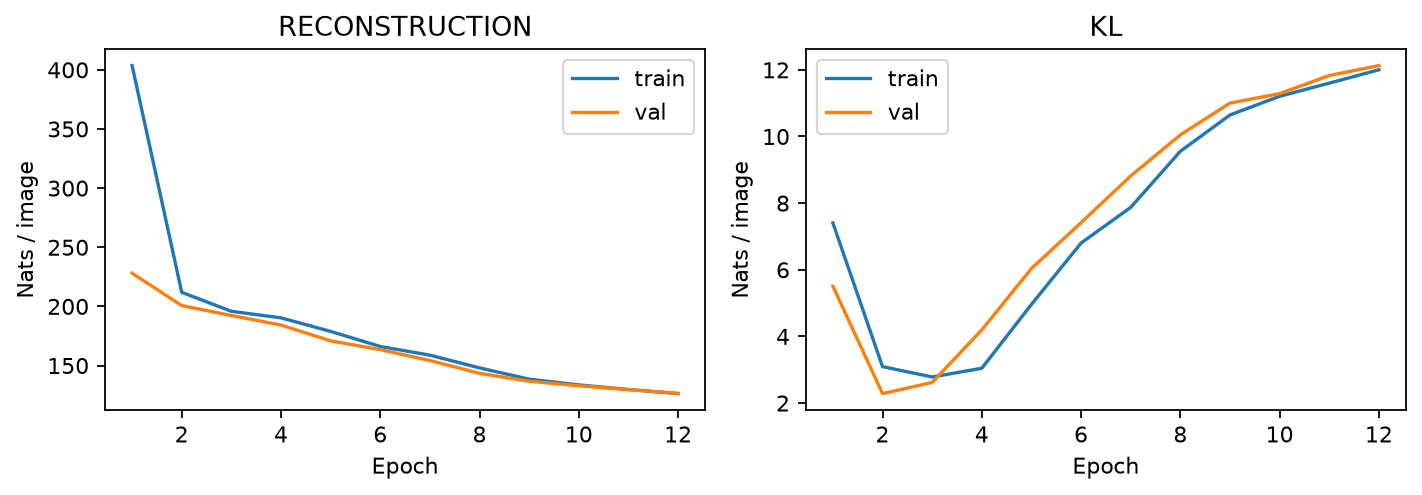

In [7]:
def save_show(fig,name):
    fig.tight_layout(); path=OUT/name; fig.savefig(path,dpi=160,bbox_inches='tight'); plt.close(fig); display(Image(filename=str(path)))
fig,axes=plt.subplots(1,2,figsize=(9,3.2))
for ax,term in zip(axes,['reconstruction','kl']):
    for split in ['train','val']:
        ax.plot([h['epoch'] for h in history],[h[split+'_'+term] for h in history],label=split)
    ax.set(xlabel='Epoch',ylabel='Nats / image',title=term.upper()); ax.legend()
save_show(fig,'training_curves.png')

In [8]:
model.load_state_dict(torch.load(OUT/'vae.pt',map_location='cpu',weights_only=True)['state_dict']); model.eval()
@torch.no_grad()
def reconstruct(x):
    return torch.cat([model.decode(model.encode(b)[0]).sigmoid() for b in x.split(BATCH)])
routes={}; rows=[]
for s,y in noisy.items():
    g=gaussian(y)
    routes[s]={'No processing':y,'Gaussian':g,'VAE':reconstruct(y),'Gaussian + VAE':reconstruct(g)}
    for name,p in routes[s].items():
        assert p.shape==test.shape and torch.isfinite(p).all() and p.min()>=0 and p.max()<=1
        rows.append(dict(noise=s,method=name,mse=(p-test).square().mean().item()))
with (OUT/'mse_results.csv').open('w',newline='') as f:
    w=csv.DictWriter(f,fieldnames=rows[0]); w.writeheader(); w.writerows(rows)
for r in rows: print(f"{r['noise']:.2f} | {r['method']:16s} | {r['mse']:.6f}")

0.15 | No processing    | 0.011214
0.15 | Gaussian         | 0.022272
0.15 | VAE              | 0.066716
0.15 | Gaussian + VAE   | 0.071018
0.30 | No processing    | 0.044781
0.30 | Gaussian         | 0.037669
0.30 | VAE              | 0.092754
0.30 | Gaussian + VAE   | 0.093928


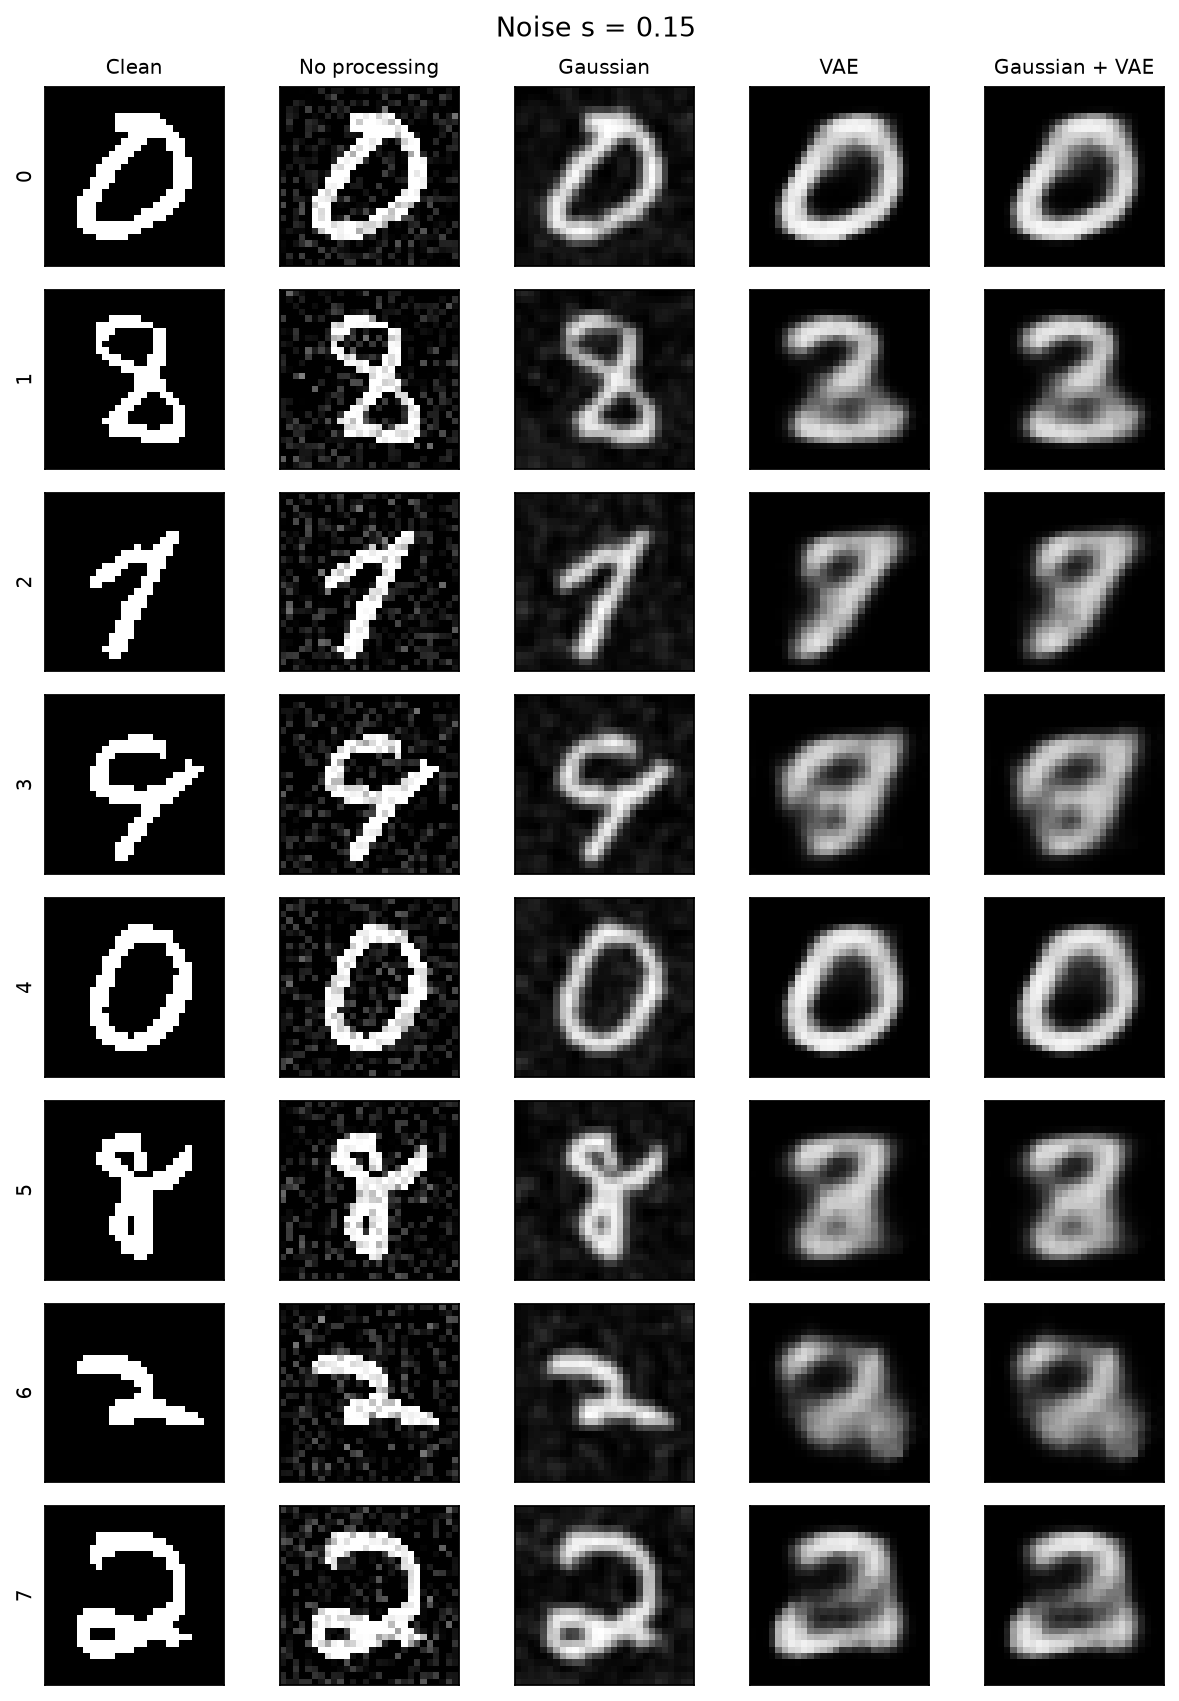

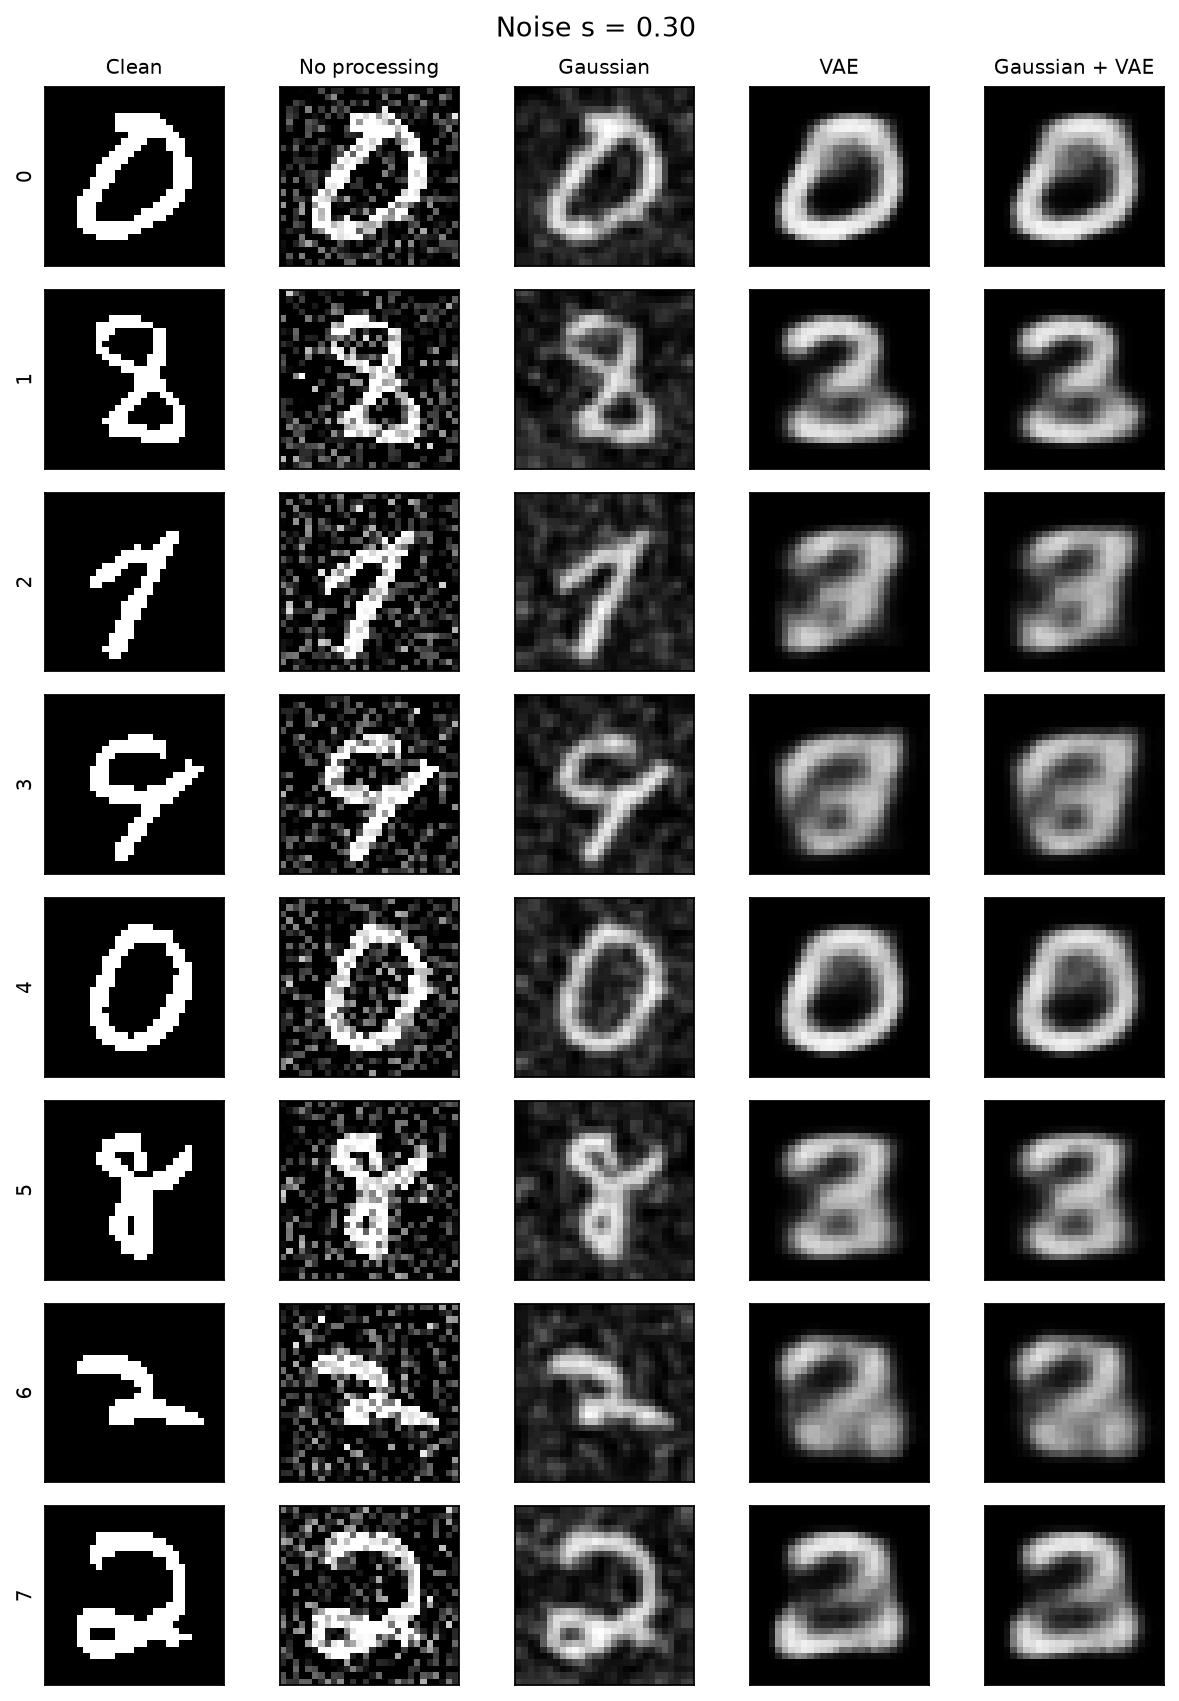

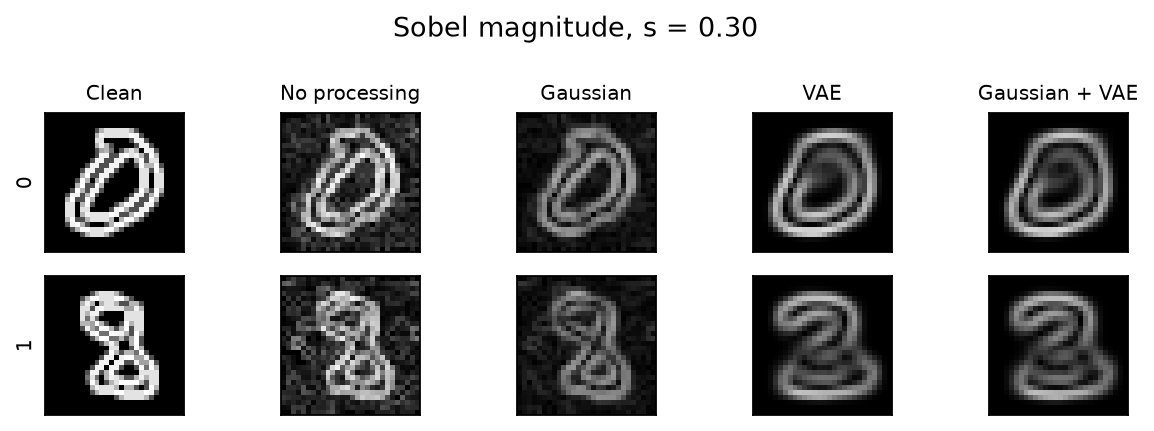

In [9]:
def grid(columns,indices,name,title,vmax=1):
    fig,axes=plt.subplots(len(indices),len(columns),figsize=(1.55*len(columns),1.35*len(indices)),squeeze=False)
    for j,(label,imgs) in enumerate(columns.items()):
        for i,idx in enumerate(indices):
            ax=axes[i,j]; ax.imshow(imgs[idx,0].numpy(),cmap='gray',vmin=0,vmax=vmax); ax.set_xticks([]); ax.set_yticks([])
            if i==0: ax.set_title(label,fontsize=9)
            if j==0: ax.set_ylabel(str(idx),fontsize=9)
    fig.suptitle(title); save_show(fig,name)
for s in LEVELS:
    grid({'Clean':test,**routes[s]},range(8),f'comparison_{s:.2f}.png',f'Noise s = {s:.2f}')
edge={k:sobel(v)[2] for k,v in {'Clean':test,**routes[0.30]}.items()}
edge_max=max(v[:2].max().item() for v in edge.values())
grid(edge,[0,1],'sobel.png','Sobel magnitude, s = 0.30',edge_max)

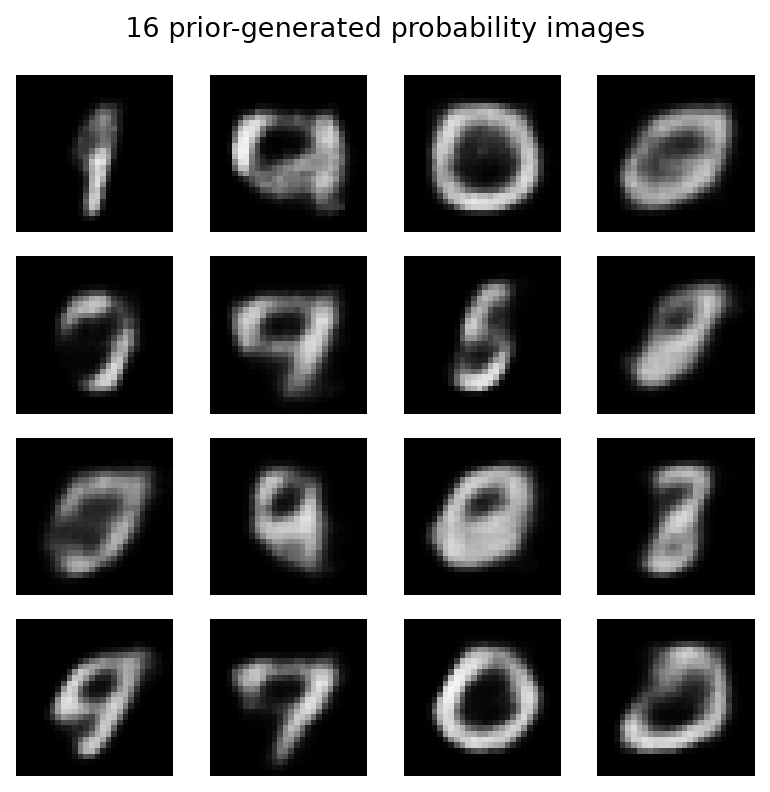

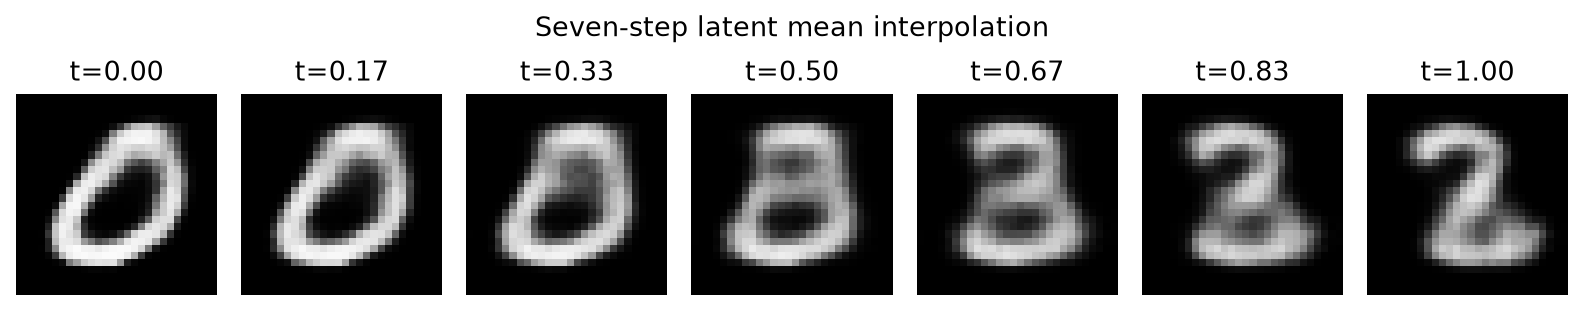

In [10]:
@torch.no_grad()
def generate():
    z=torch.randn(16,LATENT,generator=torch.Generator().manual_seed(391))
    return model.decode(z).sigmoid()
probs=generate(); fig,axes=plt.subplots(4,4,figsize=(5,5))
for ax,p in zip(axes.flat,probs):
    ax.imshow(p[0],cmap='gray',vmin=0,vmax=1); ax.axis('off')
fig.suptitle('16 prior-generated probability images'); save_show(fig,'prior.png')
with torch.no_grad():
    mu,_=model.encode(test[[0,1]])
    t=torch.linspace(0,1,7).unsqueeze(1)
    interp=model.decode((1-t)*mu[0]+t*mu[1]).sigmoid()
fig,axes=plt.subplots(1,7,figsize=(10,2))
for i,(ax,p) in enumerate(zip(axes,interp)):
    ax.imshow(p[0],cmap='gray',vmin=0,vmax=1); ax.axis('off'); ax.set_title(f't={i/6:.2f}')
fig.suptitle('Seven-step latent mean interpolation'); save_show(fig,'interpolation.png')

s=0.15: mean combined minus VAE MSE=0.004302; largest difference at index 424: 0.014111


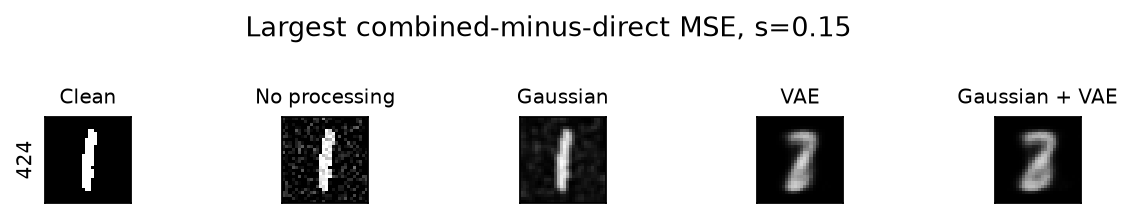

s=0.3: mean combined minus VAE MSE=0.001174; largest difference at index 367: 0.018546


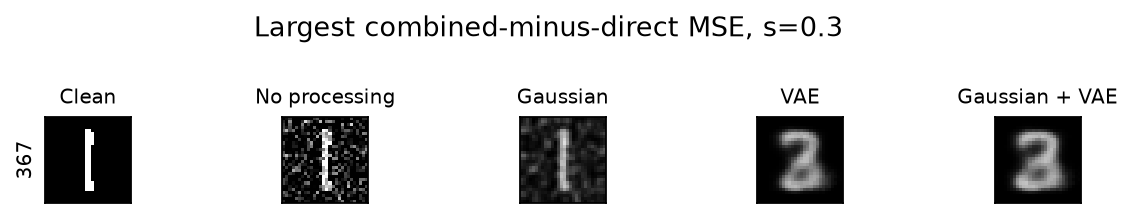

Saved outputs: C:\Users\17996\OneDrive - CityU(DG) 香港城市大学（东莞）\桌面\513CS4186 CV\Tutorial\course project\project_outputs


In [11]:
for s in LEVELS:
    a=routes[s]; direct=(a['VAE']-test).square().flatten(1).mean(1); combined=(a['Gaussian + VAE']-test).square().flatten(1).mean(1)
    delta=combined-direct; idx=int(delta.argmax())
    print(f's={s}: mean combined minus VAE MSE={delta.mean():.6f}; largest difference at index {idx}: {delta[idx]:.6f}')
    grid({'Clean':test,**a},[idx],f'failure_{s:.2f}.png',f'Largest combined-minus-direct MSE, s={s}')
print('Saved outputs:',OUT.resolve())